# 02 · Mineração, modelagem e avaliação

Lê os resultados gerados por `python -m src.pipeline` (em `reports/` e `models/`) e interpreta cada etapa: tuning do ALS, K-Means, comparação de estratégias e recomendações reais do serviço da API. Cobre os critérios 3 e 4 do projeto.

In [1]:
import json, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path('..')
meta = json.loads((ROOT/'models/metadata.json').read_text())
print('Versão do modelo:', meta['version'], '| commit', meta['git_commit'])
pd.Series(meta['data'])

Versão do modelo: 20261118-151631 | commit b878d9d


raw_events                   2756101.000
events_after_sanitization    2694458.000
train_events                  994053.000
test_events                   248514.000
n_users                       163697.000
n_items                        91087.000
matrix_sparsity_pct               99.996
dtype: float64

## 1. Tuning do ALS
7 configurações (fatores × regularização × ponderação BM25). A ponderação BM25 reduz o peso de itens muito populares e foi o fator que mais melhorou o nDCG.

In [2]:
tuning = pd.read_csv(ROOT/'reports/als_tuning.csv')
tuning

,factors,regularization,weighting,train_seconds,ndcg@5_com_historico,recall@5_com_historico,ndcg@5_pouco_historico,recall@5_pouco_historico,ndcg@5_medio
0,128,0.05,bm25,24.2,0.0182,0.0188,0.0195,0.0264,0.0188
1,64,0.01,bm25,19.8,0.0146,0.0140,0.0184,0.0229,0.0165
2,64,0.10,bm25,14.3,0.0146,0.0136,0.0184,0.0229,0.0165
3,32,0.05,bm25,11.0,0.0120,0.0127,0.0145,0.0199,0.0132
4,64,0.01,none,14.2,0.0094,0.0089,0.0097,0.0120,0.0096
5,64,0.10,none,14.1,0.0094,0.0089,0.0097,0.0120,0.0096
6,32,0.05,none,10.7,0.0071,0.0060,0.0097,0.0127,0.0084


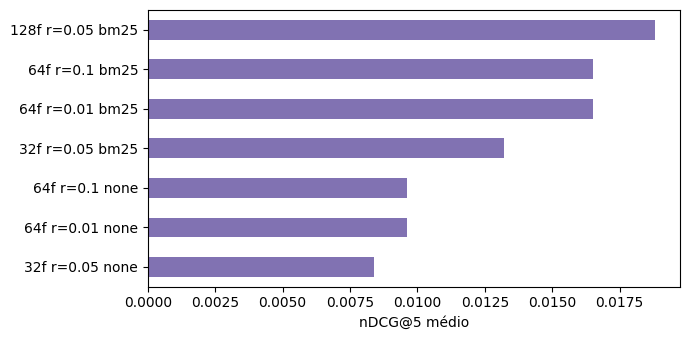

In [3]:
ax = tuning.set_index(tuning.apply(lambda r: f"{int(r.factors)}f r={r.regularization} {r.weighting}", axis=1))['ndcg@5_medio'].sort_values().plot.barh(figsize=(7,3.5), color='#8172B2')
ax.set_xlabel('nDCG@5 médio'); plt.tight_layout(); plt.show()

**Leitura:** BM25 + 128 fatores é a melhor configuração (nDCG@5 médio 0,0188), contra 0,0084 do melhor ALS sem ponderação com 32 fatores. A regularização teve pouco efeito.

## 2. K-Means: segmentação de consumidores

In [4]:
sil = pd.read_csv(ROOT/'reports/silhouette_by_k.csv'); print(sil.to_string(index=False))
profile = pd.read_csv(ROOT/'reports/cluster_profile.csv'); profile

 k  silhouette
 2    0.433055
 3    0.313497
 4    0.316801
 5    0.344196
 6    0.288591
 7    0.255272
 8    0.235828


,cluster,label,n_users,recency_days,frequency,n_unique_items,engagement_score,conversion_rate
0,0,Baixo engajamento,129189,48.91,3.62,2.33,3.95,0.02
1,1,Alto engajamento,34508,45.44,15.25,8.63,18.19,0.04


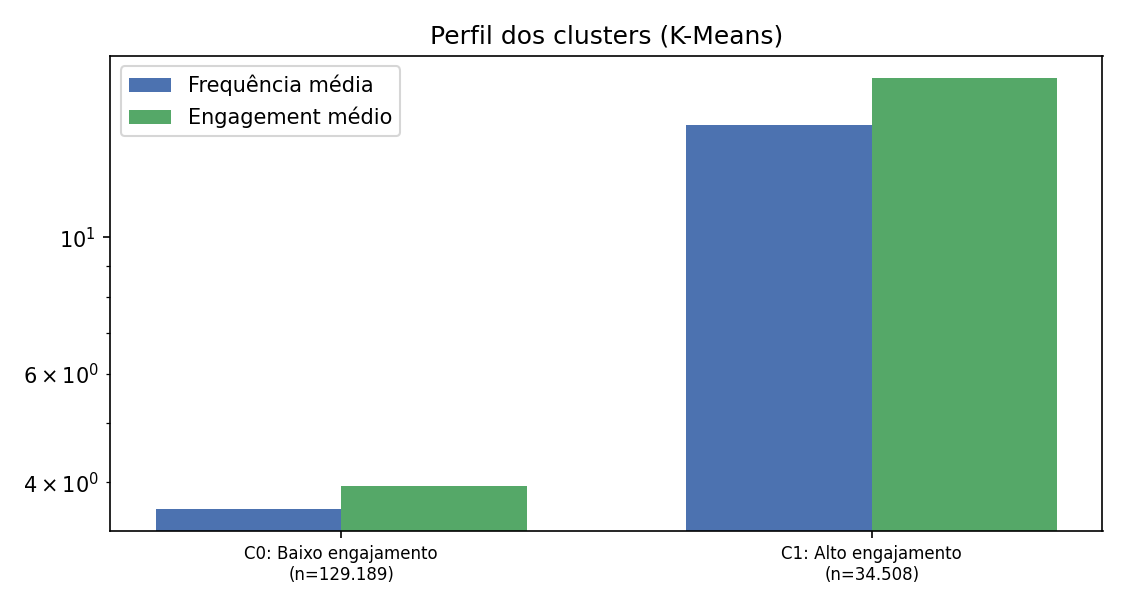

In [5]:
from IPython.display import Image
Image(str(ROOT/'reports/figures/04_cluster_profile.png'))

**Leitura:** K=2 maximiza o silhouette (0,433). O grupo de *alto engajamento* (34,5 mil usuários) tem ~4× mais eventos e o dobro da taxa de conversão do grupo de *baixo engajamento* (129 mil). K maiores têm silhouette menor; o notebook 01 mostra que, sem sanitização e `log1p`, o silhouette alto escondia um micro-cluster de outliers.

## 3. Comparação de estratégias
Protocolo: split temporal 80/20; relevantes = itens **novos** para o usuário no período de teste; 1.000 usuários por segmento; semente fixa; baselines de popularidade.

In [6]:
cmp = pd.read_csv(ROOT/'reports/strategy_comparison.csv'); cmp

,segmento,estrategia,precision@5,recall@5,ndcg@5,map@5,n_users_evaluated,catalog_coverage,latency_ms
0,com_historico,popularidade_global,0.0008,0.0026,0.0029,0.0026,1000,0.0001,0.01
1,com_historico,popularidade_por_cluster,0.0014,0.0036,0.0029,0.0020,1000,0.0001,0.00
2,com_historico,cf_memory_based,0.0074,0.0165,0.0141,0.0100,1000,0.0443,16.14
3,com_historico,cf_als,0.0094,0.0188,0.0182,0.0134,1000,0.0185,4.02
4,com_historico,hibrido_limiar_3,0.0094,0.0188,0.0182,0.0134,1000,0.0185,4.06
5,com_historico,hibrido_limiar_1,0.0094,0.0188,0.0182,0.0134,1000,0.0185,4.59
6,pouco_historico,popularidade_global,0.0010,0.0043,0.0044,0.0043,1000,0.0001,0.01
7,pouco_historico,popularidade_por_cluster,0.0014,0.0051,0.0032,0.0023,1000,0.0001,0.00
8,pouco_historico,cf_memory_based,0.0090,0.0289,0.0211,0.0163,1000,0.0403,15.88
9,pouco_historico,cf_als,0.0078,0.0264,0.0195,0.0154,1000,0.0198,4.22


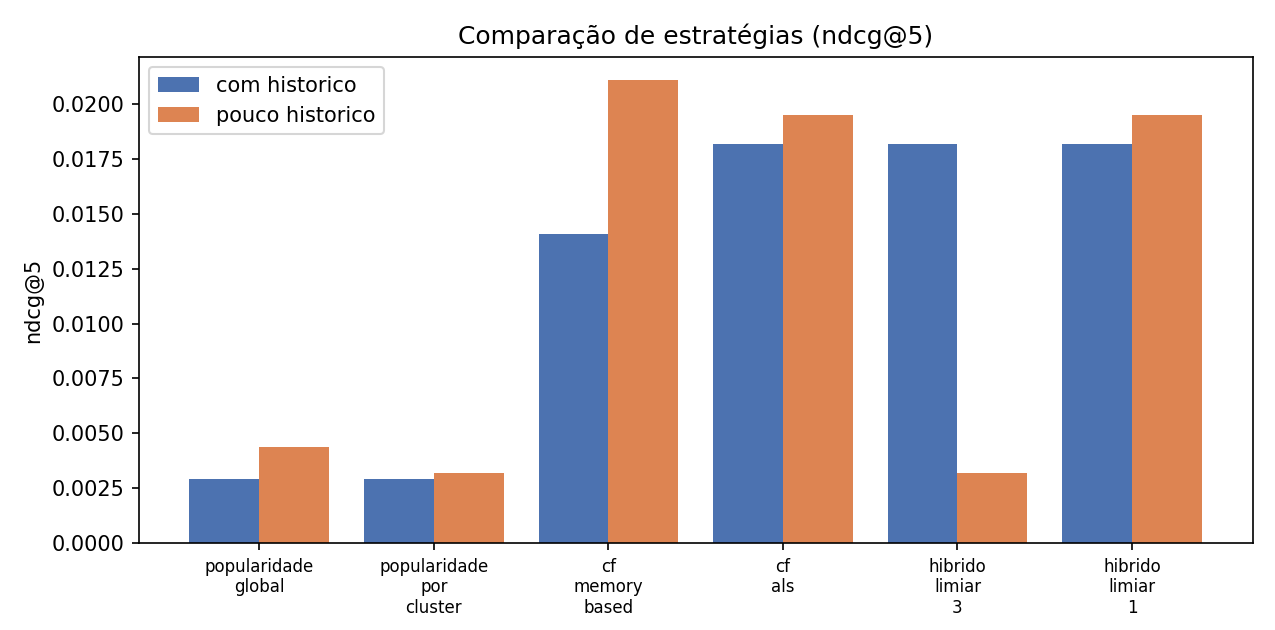

In [7]:
Image(str(ROOT/'reports/figures/05_strategy_comparison.png'))

**Leitura:**
- ALS ≈ 6× a popularidade para usuários com histórico (0,0182 vs 0,0029).
- Memory-based e ALS ficam próximos; ALS é ~4× mais rápido (4 ms vs 16 ms) — escolhido para produção.
- O híbrido com limiar 3 derruba o nDCG dos usuários de pouco histórico (0,0195 → 0,0032); com limiar 1, igual ao ALS. Por isso `HYBRID_MIN_HISTORY=1`.
- Valores absolutos baixos são esperados: 91 mil itens, feedback implícito e só itens novos contam como acerto.

## 4. Recomendações reais pelo serviço da API

In [8]:
import sys; sys.path.insert(0, '..')
import os; os.chdir('..')
from api.dependencies import get_artifacts
from api.services.recommendation_service import get_recommendations_for_user
art = get_artifacts()
for uid in [meta['demo_users']['com_historico'][0], meta['demo_users']['pouco_historico'][0], '999999999']:
    r = get_recommendations_for_user(str(uid), art, k=5)
    print(uid, r.strategy, r.segment, [p['name'] for p in r.products])

/home/claude/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


616529 collaborative_filtering_als {'cluster_id': 1, 'label': 'Alto engajamento'} ['Produto 429907', 'Produto 396491', 'Produto 347576', 'Produto 67045', 'Produto 133398']
982059 collaborative_filtering_als {'cluster_id': 0, 'label': 'Baixo engajamento'} ['Produto 350629', 'Produto 133907', 'Produto 170811', 'Produto 215596', 'Produto 437804']
999999999 cluster_popularity_fallback None ['Produto 461686', 'Produto 219512', 'Produto 7943', 'Produto 111530', 'Produto 384302']


## 5. Limitações
- Sem ratings explícitos (feedback implícito com pesos 1/3/5).
- Avaliação só offline; seria preciso teste A/B.
- K=2 gera segmentos amplos; fallback de usuário novo usa o maior cluster.
- Sem metadados de conteúdo (dataset anonimizado), logo nada de recomendação por conteúdo.